# Session 2: Introduction to Supervised Learning & Regression
**Week 3 | AI and Machine Learning Track**

### Learning objectives
By the end of this session, you will be able to:
1. Explain what supervised learning is (features, labels, training, prediction)
2. Explain what regression is and when to use it
3. Split data into training and testing sets
4. Train a Linear Regression model and make predictions
5. Read the coefficients of a model in plain language

## 1. What is Supervised Learning?
In supervised learning, we give the model **examples that already have the right answer**, and it learns the pattern.

| Term | Meaning | Example |
|---|---|---|
| **Features (X)** | The inputs the model uses | hours studied, house size |
| **Label / Target (y)** | The answer we want to predict | exam score, house price |
| **Training** | The model learns from known examples | `model.fit(X_train, y_train)` |
| **Prediction** | The model answers for new data | `model.predict(X_new)` |

**Regression** = predicting a **number** (a continuous value), like a score, a price or a temperature.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Make results the same every time we run the notebook
np.random.seed(42)

## 2. Our first dataset: Study hours vs Exam score

In [ ]:
students =pd.read_csv("students.csv")
students.head()
print(students.isnull().sum())

AttributeError: 'function' object has no attribute 'sum'

In [ ]:
students = pd.read_csv("students.csv")

In [ ]:
students =pd.read_csv("student.csv")

In [ ]:
# Always inspect your data first (Week 2 skills!)
print(students.shape)
print(students.isnull().sum())
students.describe()

(100, 2)
hours_studied    0
exam_score       0
dtype: int64


,hours_studied,exam_score
count,100.000000,100.000000
mean,5.233000,61.381000
std,2.681438,16.025168
min,1.000000,33.800000
25%,2.775000,47.575000
50%,5.150000,59.200000
75%,7.600000,75.525000
max,9.900000,93.200000


In [ ]:
students

,hours_studied,exam_score
0,4.4,56.7
1,9.6,85.8
2,7.6,76.0
3,6.4,58.4
4,2.4,43.3
...,...,...
95,5.4,58.6
96,5.7,63.8
97,4.8,60.8
98,1.2,38.8


In [ ]:
plt.scatter(students["hours_studied"], students["exam_score"])

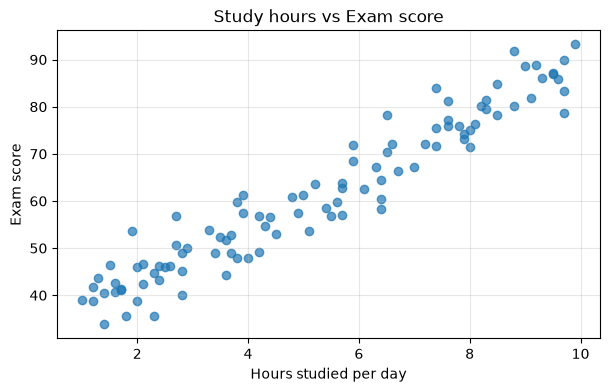

In [ ]:
plt.figure(figsize=(7, 4))
plt.scatter(students["hours_studied"], students["exam_score"], alpha=0.7)
plt.xlabel("Hours studied per day")
plt.ylabel("Exam score")
plt.title("Study hours vs Exam score")
plt.grid(alpha=0.3)
plt.show()

**Discussion:** What pattern do you see? If a new student studies 7 hours, roughly what score would you guess? A regression model does this guessing mathematically.

## 3. Separate Features (X) and Label (y)

In [ ]:
X = students[["hours_studied"]]   # features: double brackets keep it as a table (DataFrame)
y = students["exam_score"]        # label: what we want to predict

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (100, 1)
y shape: (100,)


## 4. Train-Test Split
We **never test a model on the same data it learned from**. That would be like giving students the exam questions in advance.

So we split the data:
- **Training set (80%)**: the model learns from this
- **Testing set (20%)**: kept hidden, used later to check how well the model really performs

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training rows:", X_train.shape[0])
print("Testing rows: ", X_test.shape[0])

Training rows: 80
Testing rows:  20


## 5. Train a Linear Regression model
Linear regression finds the **straight line of best fit** through the data:

`score = intercept + (coefficient × hours)`

In [ ]:
model = LinearRegression()
model.fit(X_train, y_train)      # <-- this is the "learning" step

print("Intercept:  ", round(model.intercept_, 2))
print("Coefficient:", round(model.coef_[0], 2))

Intercept:   30.99
Coefficient: 5.77


### Reading the result in plain language
- **Intercept**: the predicted score for a student who studies 0 hours.
- **Coefficient**: for every **1 extra hour** of study, the predicted score goes up by about this many marks.

(We built the data with a base of 30 and 6 marks per hour, so the model should land close to that.)

## 6. Make predictions on the test set

In [ ]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Hours": X_test["hours_studied"].values,
    "Actual score": y_test.values,
    "Predicted score": y_pred.round(1),
})
results["Difference"] = (results["Actual score"] - results["Predicted score"]).round(1)
results.head(10)

,Hours,Actual score,Predicted score,Difference
0,1.6,42.7,40.2,2.5
1,9.1,81.8,83.5,-1.7
2,8.0,71.5,77.1,-5.6
3,7.0,67.2,71.4,-4.2
4,3.3,53.9,50.0,3.9
5,5.0,61.3,59.8,1.5
6,3.6,51.8,51.8,0.0
7,8.8,91.9,81.7,10.2
8,1.2,41.7,37.9,3.8
9,4.4,56.7,56.4,0.3


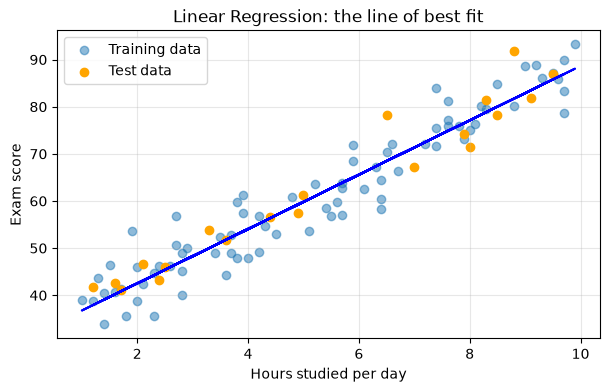

In [ ]:
plt.figure(figsize=(7, 4))
plt.scatter(X_train, y_train, alpha=0.5, label="Training data")
plt.scatter(X_test, y_test, color="orange", label="Test data")

plt.plot(X_train,model.predict(X_train),color="blue")
plt.xlabel("Hours studied per day")
plt.ylabel("Exam score")
plt.title("Linear Regression: the line of best fit")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 7. Predict for a brand-new student

In [ ]:
new_student = pd.DataFrame({"hours_studied": [6.5]})
predicted = model.predict(new_student)
print(f"A student who studies 6.5 hours is predicted to score about {predicted[0]:.1f}")

A student who studies 6.5 hours is predicted to score about 68.5


## 8. Multiple Linear Regression: more than one feature
Real problems usually have **several features**. Let's predict **house prices** from size, bedrooms, age of the house and distance from the city centre.

(This is a made-up dataset for learning purposes.)

In [ ]:
houses= pd.read_csv("houses.csv")
houses

,size_sqm,bedrooms,age_years,distance_km,price_million
0,225,4,38,28.9,88.0
1,246,5,9,2.4,123.0
2,75,1,36,27.6,3.5
3,296,4,12,8.9,142.3
4,117,2,34,10.3,53.3
...,...,...,...,...,...
195,125,5,20,18.3,57.8
196,56,4,10,28.6,19.2
197,170,2,33,19.3,51.3
198,275,5,37,3.0,125.8


In [ ]:
# Which features relate most to price?
houses.corr().round(2)["price_million"].sort_values(ascending=False)

price_million    1.00
size_sqm         0.95
bedrooms         0.17
age_years       -0.05
distance_km     -0.19
Name: price_million, dtype: float64

In [ ]:
X = houses.drop(columns="price_million")
y = houses["price_million"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

house_model = LinearRegression()
house_model.fit(X_train, y_train)

print("Intercept:", round(house_model.intercept_, 2))
coef_table = pd.DataFrame({"Feature": X.columns, "Coefficient": house_model.coef_.round(3)})
coef_table

Intercept: 4.57


,Feature,Coefficient
0,size_sqm,0.453
1,bedrooms,2.901
2,age_years,-0.306
3,distance_km,-0.790


### Interpreting the coefficients
- A **positive** coefficient means the price goes **up** as that feature increases (e.g. `size_sqm`).
- A **negative** coefficient means the price goes **down** (e.g. `age_years`, `distance_km`).
- The number tells you **how much** the price changes for each 1-unit increase, holding the other features constant.

In [ ]:
# Predict the price of a new house
new_house = pd.DataFrame({
    "size_sqm": [150], "bedrooms": [3], "age_years": [5], "distance_km": [10.0]
})
price = house_model.predict(new_house)
print(f"Predicted price: about N{price[0]:.1f} million")

Predicted price: about N71.7 million


In [ ]:
# Compare a few actual vs predicted prices from the test set
preds = house_model.predict(X_test)
comparison = pd.DataFrame({"Actual": y_test.values, "Predicted": preds.round(1)}).head(8)
comparison["Difference"] = (comparison["Actual"] - comparison["Predicted"]).round(1)
comparison

,Actual,Predicted,Difference
0,77.3,73.2,4.1
1,34.1,40.7,-6.6
2,99.0,100.7,-1.7
3,41.0,35.8,5.2
4,40.7,46.5,-5.8
5,58.4,69.9,-11.5
6,49.2,31.2,18.0
7,54.6,61.4,-6.8


In [ ]:
import statsmodels.api as sm

In [ ]:
X = sm.add_constant(X)

In [ ]:
model = sm.OLS(y, X).fit() 
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:          price_million   R-squared:                       0.973
Model:                            OLS   Adj. R-squared:                  0.972
Method:                 Least Squares   F-statistic:                     1751.
Date:                Mon, 05 Oct 2026   Prob (F-statistic):          1.47e-151
Time:                        13:55:09   Log-Likelihood:                -631.55
No. Observations:                 200   AIC:                             1273.
Df Residuals:                     195   BIC:                             1290.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
===============================================================================
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const           4.7657      1.652      2.885      0.004       1.508       8.024
size_sqm        0.4518      0.006     80.662      0.000       0.441       0.463
bedrooms        2.8203      0.283      9.964      0.000       2.262       3.379
age_years      -0.2718      0.034     -7.941      0.000      -0.339      -0.204
distance_km    -0.8208      0.047    -17.303      0.000      -0.914      -0.727
==============================================================================
Omnibus:                        1.636   Durbin-Watson:                   1.913
Prob(Omnibus):                  0.441   Jarque-Bera (JB):                1.275
Skew:                          -0.162   Prob(JB):                        0.529
Kurtosis:                       3.219   Cond. No.                         786.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [ ]:
def backward_elimination(X, y, significance_level=0.05):
    while True:
        model = sm.OLS(y, X).fit()
        max_p_value = model.pvalues.max()  # Get highest p-value
        if max_p_value > significance_level:
            excluded_feature = model.pvalues.idxmax()
            print(f"Removing '{excluded_feature}' with p-value {max_p_value:.4f}")
            X = X.drop(columns=[excluded_feature])
        else:
            break
    return model

In [ ]:
final_model = backward_elimination(X, y)
print(final_model.summary())

                            OLS Regression Results                            
Dep. Variable:          price_million   R-squared:                       0.973
Model:                            OLS   Adj. R-squared:                  0.972
Method:                 Least Squares   F-statistic:                     1751.
Date:                Mon, 05 Oct 2026   Prob (F-statistic):          1.47e-151
Time:                        13:55:10   Log-Likelihood:                -631.55
No. Observations:                 200   AIC:                             1273.
Df Residuals:                     195   BIC:                             1290.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const           4.7657      1.652      2.885      

> **Coming up in Session 4:** we will learn how to measure *how good* these predictions really are using MAE, RMSE and R².

## Practice exercises
1. Change `test_size` to `0.3` and re-run the study-hours model. Does the coefficient change? Why might it?
2. Predict the exam score for a student who studies **2 hours** and one who studies **9 hours**.
3. In the house model, predict the price of a house that is **200 sqm, 4 bedrooms, 10 years old, 5 km** from the centre.
4. **Challenge:** remove the `distance_km` feature, retrain the model and compare the predictions for the same house.

## Key takeaways
- Supervised learning learns from **labelled examples** (features + known answer).
- **Regression** predicts a **number**.
- Always **split** your data into train and test sets.
- `fit()` trains the model, `predict()` uses it.
- Coefficients tell us how each feature influences the prediction.